<a href="https://colab.research.google.com/github/RETNO26MA41D019/EDA-Cart-Abandonment/blob/main/Deteksi_Pengabaian_Keranjang_Belanja_(Cart_Abandonment)_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LAPORAN EXPLORATORY DATA ANALYSIS (EDA)
## Deteksi Dini Pengabaian Keranjang Belanja (*E-Commerce Cart Abandonment*) Menggunakan Analisis Perilaku Sesi Pengunjung

---

## Bab 1: Pendahuluan & Memahami Masalah (*Understanding the Problem*)

### 1.1 Latar Belakang Masalah dan Tujuan Utama
Dalam industri *e-commerce*, tingkat pengabaian sesi atau keranjang belanja (*cart abandonment*) merupakan tantangan bisnis utama yang menyebabkan hilangnya potensi pendapatan secara langsung. Sebagian besar pengunjung menelusuri halaman produk dan administratif, namun meninggalkan situs tanpa menyelesaikan transaksi (`Revenue = False`).
* **Masalah Bisnis:** Tingginya proporsi sesi pengunjung yang tidak berakhir pada konversi pembelian (84,37% sesi berakhir tanpa transaksi).
* **Tujuan Utama:** Mengidentifikasi pola perilaku navigasi pengguna, kualitas interaksi halaman, dan faktor temporal yang membedakan pengunjung yang membeli (`Revenue = 1`) dengan pengunjung yang meninggalkan sesi (`Revenue = 0`), serta membangun *pipeline* pra-pemrosesan dan model klasifikasi dini untuk memprediksi potensi konversi/pengabaian sesi secara *real-time*.

### 1.2 Tipe Masalah
Permasalahan ini merupakan **Klasifikasi Biner (*Binary Classification*)** dengan variabel target `Revenue`:
* **Kelas `0` (`False`):** Sesi berakhir tanpa pembelian (*Cart/Session Abandonment* — kelas mayoritas).
* **Kelas `1` (`True`):** Sesi berakhir dengan transaksi pembelian (*Purchase Conversion* — kelas minoritas).

### 1.3 Metrik Keberhasilan
Karena distribusi kelas target tidak seimbang (*imbalanced dataset* dengan rasio ~84,4% : 15,6%), metrik *Accuracy* saja dapat menyesatkan. Oleh karena itu, keberhasilan model dievaluasi menggunakan:
1. **ROC-AUC Score:** Mengukur kemampuan model membedakan kelas pembeli dan non-pembeli di seluruh ambang batas (*threshold*).
2. **Recall (*Sensitivity*) pada Kelas Positif (`1`):** Memastikan sebanyak mungkin sesi potensial pembeli berhasil terdeteksi.
3. **F1-Score pada Kelas Positif (`1`):** Menjaga keseimbangan harmonis antara *Precision* dan *Recall* agar intervensi promosi tepat sasaran. teks tebal

## Bab 2: Memahami Data (*Understanding the Data*)

### 2.1 Pengumpulan Data (*Data Collection*)
* **Identifikasi Sumber Data:** Dataset *Online Shoppers Purchasing Intention* yang bersumber dari repositori publik Kaggle (`imakash3011/online-shoppers-purchasing-intention-dataset`) dalam format file CSV (`online_shoppers_intention.csv`). Dataset ini merekam jejak klik (*clickstream*) dan metrik Google Analytics dari 12.330 sesi pengunjung unik selama periode 1 tahun.
* **Akses dan Ekstraksi Data:** Data diekstraksi secara terprogram menggunakan pustaka `kagglehub` di lingkungan Google Colab dan dimuat ke dalam struktur DataFrame `pandas` menggunakan `pd.read_csv()`.

### 2.2 Deskripsi dan Eksplorasi Awal Data
Dataset mentah memiliki dimensi **12.330 baris (sesi)** dan **18 kolom (atribut)** yang terdiri atas:
* **10 Fitur Numerik (`int64` & `float64`):** `Administrative`, `Administrative_Duration`, `Informational`, `Informational_Duration`, `ProductRelated`, `ProductRelated_Duration`, `BounceRates`, `ExitRates`, `PageValues`, dan `SpecialDay`.
* **8 Fitur Kategorikal/Boolean (`object`, `int64` kode kategori, & `bool`):** `Month`, `OperatingSystems`, `Browser`, `Region`, `TrafficType`, `VisitorType`, `Weekend`, serta variabel target `Revenue`.

### 2.3 Peninjauan Kualitas Data (*Data Quality Assessment*)
* **Missing Values:** Pemeriksaan nilai kosong (`NaN`/`null`) pada seluruh 18 kolom.
* **Data Duplikat:** Deteksi baris duplikat penuh yang berpotensi membiaskan perhitungan statistik dan evaluasi model.
* **Outliers (Pencilan):** Identifikasi nilai ekstrem pada fitur durasi kunjungan dan `PageValues`.
* **Konsistensi Format:** Penyeragaman tipe data boolean (`Weekend`, `Revenue`) menjadi biner (`0`/`1`) dan pengkodean fitur kategorikal nominal (`OperatingSystems`, `Browser`, `Region`, `TrafficType`) agar tidak disalahartikan sebagai angka kontinu.

### 2.4 Eksplorasi Visual Awal
Dilakukan pemetaan sebaran distribusi target (`Revenue`), tingkat konversi per segmen pengunjung (`VisitorType`), distribusi kurva *histogram + KDE*, serta matriks korelasi antar variabel.

### 2.5 Penyelarasan dengan Kebutuhan Bisnis (*Business-Data Alignment*)
* **Asesmen Nilai Data:** Fitur perilaku halaman (`PageValues`, `ExitRates`, `ProductRelated_Duration`) sangat relevan secara bisnis karena merepresentasikan intensi belanja pengguna secara langsung.
* **Kebutuhan Rekayasa Fitur Awal:** Diperlukan pembuatan fitur rasio dan agregasi seperti total halaman (`Total_Pages`), total durasi (`Total_Duration`), rata-rata waktu per halaman (`Avg_Time_Per_Page`), rasio halaman produk (`Product_Page_Ratio`), dan indikator halaman bernilai komersial (`Has_PageValue`).

## Bab 3: Memuat & Memeriksa Data (*Importing and Inspecting the Data*)
### 3.1 Import Library dan Loading Dataset


In [1]:
# Instalasi pustaka pendukung
!pip install -q kagglehub missingno xgboost shap scikit-learn seaborn matplotlib pandas numpy scipy

import os
import warnings
warnings.filterwarnings('ignore')

import kagglehub
import pandas as pd
import numpy as np
import missingno as msno
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    f1_score, recall_score, precision_score, RocCurveDisplay
)

import xgboost as xgb
import shap

# Konfigurasi tampilan grafik
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)

# 3.1 Loading Dataset dari Kaggle (CSV)
path = kagglehub.dataset_download("imakash3011/online-shoppers-purchasing-intention-dataset")
csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
file_path = os.path.join(path, csv_files[0])

df_raw = pd.read_csv(file_path)
print(f"File CSV berhasil dimuat dari: {file_path}")

# 3.2 Inspeksi Dimensi dan Struktur Data
print(f"\n=== 3.2 DIMENSI & DAFTAR KOLOM ===")
print(f"Total Baris: {df_raw.shape[0]} | Total Kolom: {df_raw.shape[1]}")
print("Daftar Kolom:", df_raw.columns.tolist())
display(df_raw.head())

# 3.3 Pemeriksaan Tipe Data dan Informasi Umum
print("\n=== 3.3 INFORMASI TIPE DATA (df.info) ===")
df_raw.info()

# 3.4 Ringkasan Statistik Awal (Numerik & Kategorikal)
print("\n=== 3.4 RINGKASAN STATISTIK AWAL (NUMERIK) ===")
display(df_raw.describe().round(3))

print("\n=== 3.4 RINGKASAN STATISTIK AWAL (KATEGORIKAL & BOOLEAN) ===")
cat_raw_cols = ['Month', 'VisitorType', 'Weekend', 'Revenue']
display(df_raw[cat_raw_cols].astype(str).describe())

100%|██████████| 252k/252k [00:00<00:00, 59.5MB/s]

Extracting files...
File CSV berhasil dimuat dari: /root/.cache/kagglehub/datasets/imakash3011/online-shoppers-purchasing-intention-dataset/versions/1/online_shoppers_intention.csv

=== 3.2 DIMENSI & DAFTAR KOLOM ===
Total Baris: 12330 | Total Kolom: 18
Daftar Kolom: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False



=== 3.3 INFORMASI TIPE DATA (df.info) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 no

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000,12330.000,12330.000,12330.000,12330.000,12330.000,12330.000,12330.000,12330.000,12330.000,12330.000,12330.000,12330.000,12330.000
mean,2.315,80.819,0.504,34.472,31.731,1194.746,0.022,0.043,5.889,0.061,2.124,2.357,3.147,4.070
std,3.322,176.779,1.270,140.749,44.476,1913.669,0.048,0.049,18.568,0.199,0.911,1.717,2.402,4.025
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000,1.000,1.000
25%,0.000,0.000,0.000,0.000,7.000,184.138,0.000,0.014,0.000,0.000,2.000,2.000,1.000,2.000
50%,1.000,7.500,0.000,0.000,18.000,598.937,0.003,0.025,0.000,0.000,2.000,2.000,3.000,2.000
75%,4.000,93.256,0.000,0.000,38.000,1464.157,0.017,0.050,0.000,0.000,3.000,2.000,4.000,4.000
max,27.000,3398.750,24.000,2549.375,705.000,63973.522,0.200,0.200,361.764,1.000,8.000,13.000,9.000,20.000



=== 3.4 RINGKASAN STATISTIK AWAL (KATEGORIKAL & BOOLEAN) ===


,Month,VisitorType,Weekend,Revenue
count,12330,12330,12330,12330
unique,10,3,2,2
top,May,Returning_Visitor,False,False
freq,3364,10551,9462,10422


## Bab 4: Penanganan Data yang Hilang (*Handling Missing Data*)

### 4.1 Identifikasi dan Visualisasi Nilai yang Hilang
Pemeriksaan dilakukan menggunakan `df.isnull().sum()`, perhitungan persentase nilai kosong, serta matriks visualisasi dari pustaka `missingno`.

### 4.2 Analisis Mekanisme Missing Data (*MCAR / MAR / MNAR*)
Secara teoretis, mekanisme data hilang terbagi menjadi:
* **MCAR (*Missing Completely at Random*):** Kehilangan data bersifat acak murni dan tidak bergantung pada variabel apa pun.
* **MAR (*Missing at Random*):** Kehilangan data dipengaruhi oleh variabel lain yang teramati dalam dataset.
* **MNAR (*Missing Not at Random*):** Kehilangan data berkaitan langsung dengan nilai variabel itu sendiri yang tidak tercatat.

Pada dataset ini, seluruh 18 kolom tercatat lengkap (**0% missing values**). Namun, ditemukan **125 baris duplikat penuh (1,01%)** yang berasal dari sesi *bounce* identik tanpa aktivitas halaman.

### 4.3 Strategi Eliminasi (*Deletions*) & 4.4 Strategi Imputasi (*Imputation Methods*)
* **Keputusan Eliminasi & Imputasi:** Karena persentase *missing values* bernilai **0%**, metode penghapusan kolom/baris akibat `NaN` (`dropna`) maupun imputasi statistik (`mean`/`median`/`mode`) dan model (`KNNImputer`/`MICE`) **tidak perlu diterapkan** pada nilai kosong.
* **Deduplikasi:** Penghapusan 125 baris duplikat penuh dilakukan (`drop_duplicates()`) agar distribusi statistik dan pelatihan model tidak bias, menyisakan **12.205 baris bersih**.

=== 4.1 TABEL PEMERIKSAAN MISSING VALUES ===


,Jumlah_Missing,Persentase (%)
Administrative,0,0.0
Administrative_Duration,0,0.0
Informational,0,0.0
Informational_Duration,0,0.0
ProductRelated,0,0.0
ProductRelated_Duration,0,0.0
BounceRates,0,0.0
ExitRates,0,0.0
PageValues,0,0.0
SpecialDay,0,0.0


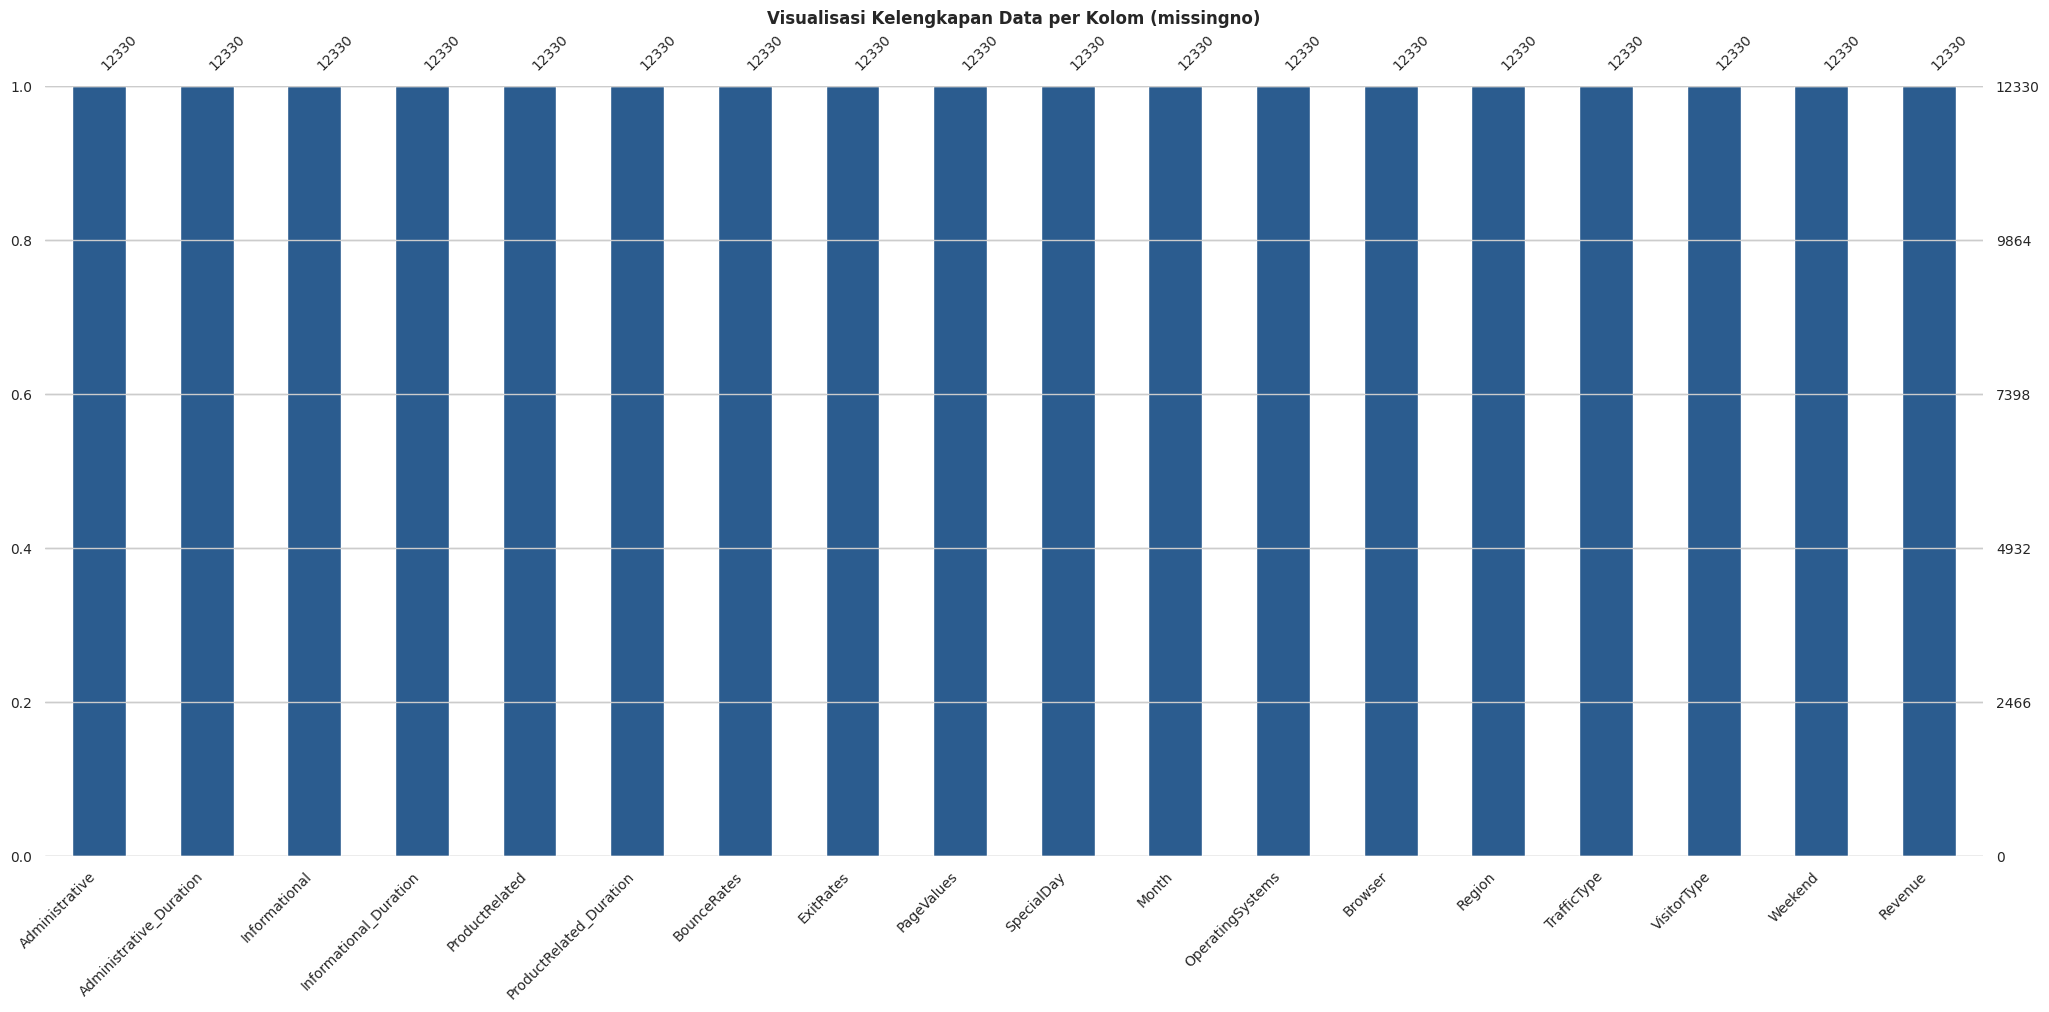

Jumlah baris duplikat ditemukan: 125 (1.01%)
Dimensi dataset bersih setelah deduplikasi: 12205 baris x 18 kolom


In [2]:
# 4.1 Identifikasi & Persentase Missing Values
missing_df = pd.DataFrame({
    'Jumlah_Missing': df_raw.isnull().sum(),
    'Persentase (%)': (df_raw.isnull().sum() / len(df_raw)) * 100
})
print("=== 4.1 TABEL PEMERIKSAAN MISSING VALUES ===")
display(missing_df)

# Visualisasi Missing Data dengan missingno
plt.figure(figsize=(10, 3))
msno.bar(df_raw, color="#2b5c8f", fontsize=10)
plt.title("Visualisasi Kelengkapan Data per Kolom (missingno)", fontsize=12, fontweight='bold')
plt.show()

# Penanganan Duplikat & Konsistensi Tipe Data (Bab 2.3 & 4.3)
dup_count = df_raw.duplicated().sum()
print(f"Jumlah baris duplikat ditemukan: {dup_count} ({dup_count/len(df_raw)*100:.2f}%)")

df = df_raw.drop_duplicates().copy()
df['Weekend'] = df['Weekend'].astype(int)
df['Revenue'] = df['Revenue'].astype(int)  # 1 = Membeli, 0 = Tidak Membeli (Abandonment)
print(f"Dimensi dataset bersih setelah deduplikasi: {df.shape[0]} baris x {df.shape[1]} kolom")

## Bab 5: Eksplorasi Karakteristik Data (*Exploring Data Characteristics*)

### 5.1 Analisis Statistik Deskriptif Data Numerik
Menampilkan ukuran pemusatan (*mean*, *median*, *modus*) serta ukuran penyebaran (*standar deviasi*, *varians*, *min*, *max*, kuartil *Q1, Q2, Q3*, dan *IQR*).

### 5.2 Analisis Bentuk Distribusi Data (*Skewness* dan *Kurtosis*)
* **Skewness:** Seluruh 10 variabel numerik memiliki *skewness* positif ekstrem (**> 1,9**), menandakan kurva menceng kanan (*right-skewed*) di mana mayoritas sesi memiliki durasi dan nilai halaman kecil, sementara sebagian kecil sesi sangat panjang.
* **Kurtosis:** Seluruh variabel memiliki nilai *excess kurtosis* positif tinggi (**> 4,6**), mengindikasikan distribusi **leptokurtik** (puncak tajam di dekat nol dengan ekor tebal yang memuat banyak nilai ekstrem/pencilan).

=== 5.1 & 5.2 TABEL STATISTIK DESKRIPTIF, SKEWNESS, & KURTOSIS ===


,count,mean,median,modus,std,varians,min,25%,75%,max,iqr,skewness,kurtosis
Administrative,12205.0,2.339,1.000,0.0,3.330,11.092,0.0,0.000,4.000,27.000,4.000,1.947,4.641
Administrative_Duration,12205.0,81.646,9.000,0.0,177.492,31503.355,0.0,0.000,94.700,3398.750,94.700,5.592,50.137
Informational,12205.0,0.509,0.000,0.0,1.276,1.627,0.0,0.000,0.000,24.000,0.000,4.014,26.659
Informational_Duration,12205.0,34.825,0.000,0.0,141.425,20000.976,0.0,0.000,0.000,2549.375,0.000,7.540,75.534
ProductRelated,12205.0,32.046,18.000,1.0,44.594,1988.594,0.0,8.000,38.000,705.000,30.000,4.333,31.073
ProductRelated_Duration,12205.0,1206.982,608.943,0.0,1919.601,3684869.536,0.0,193.000,1477.155,63973.522,1284.155,7.253,136.681
BounceRates,12205.0,0.020,0.003,0.0,0.045,0.002,0.0,0.000,0.017,0.200,0.017,3.162,9.334
ExitRates,12205.0,0.041,0.025,0.2,0.046,0.002,0.0,0.014,0.049,0.200,0.034,2.235,4.642
PageValues,12205.0,5.950,0.000,0.0,18.654,347.959,0.0,0.000,0.000,361.764,0.000,6.351,64.998
SpecialDay,12205.0,0.062,0.000,0.0,0.200,0.040,0.0,0.000,0.000,1.000,0.000,3.286,9.798


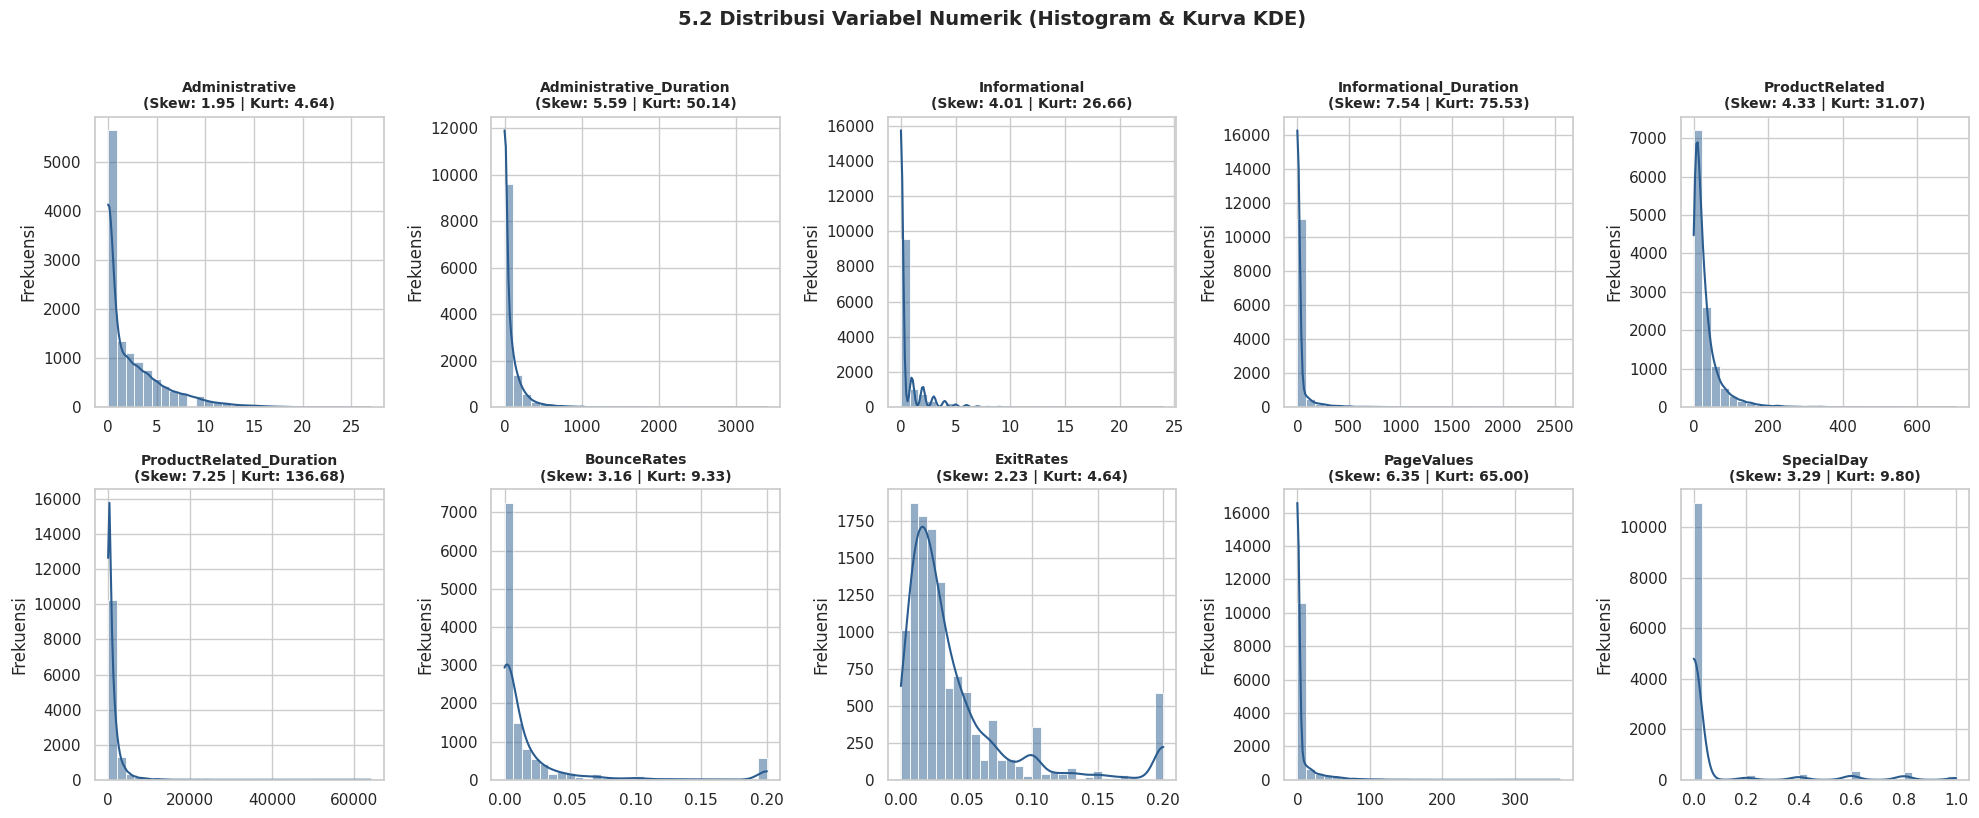

In [3]:
num_cols = [
    'Administrative', 'Administrative_Duration',
    'Informational', 'Informational_Duration',
    'ProductRelated', 'ProductRelated_Duration',
    'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay'
]

# 5.1 & 5.2 Tabel Statistik Deskriptif Lengkap
desc = df[num_cols].describe().T
desc['median'] = df[num_cols].median()
desc['modus'] = df[num_cols].mode().iloc[0]
desc['varians'] = df[num_cols].var()
desc['iqr'] = desc['75%'] - desc['25%']
desc['skewness'] = df[num_cols].skew()
desc['kurtosis'] = df[num_cols].kurt()

print("=== 5.1 & 5.2 TABEL STATISTIK DESKRIPTIF, SKEWNESS, & KURTOSIS ===")
display(desc[['count', 'mean', 'median', 'modus', 'std', 'varians', 'min', '25%', '75%', 'max', 'iqr', 'skewness', 'kurtosis']].round(3))

# 5.2 Visualisasi Histogram + Garis KDE untuk Seluruh Variabel Numerik
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for idx, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[idx], color='#2b5c8f', bins=30)
    axes[idx].set_title(f"{col}\n(Skew: {df[col].skew():.2f} | Kurt: {df[col].kurt():.2f})", fontsize=10, fontweight='bold')
    axes[idx].set_xlabel("")
    axes[idx].set_ylabel("Frekuensi")

plt.suptitle("5.2 Distribusi Variabel Numerik (Histogram & Kurva KDE)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Bab 6: Transformasi Data (*Performing Data Transformation*)

### 6.1 Transformasi untuk Memperbaiki Distribusi (*Handling Skewness*)
Untuk model berbasis linear/jarak (seperti *Logistic Regression*), fitur numerik yang sangat menceng kanan ditransformasikan menggunakan fungsi logaritma $\log(x + 1)$ (`np.log1p`) agar distribusi mendekati simetris. Sedangkan untuk model berbasis pohon (*XGBoost*), fitur asli dipertahankan karena *decision tree* invarian terhadap transformasi monotonik.

### 6.2 Transformasi Skala (*Scaling & Normalization*)
* **StandardScaler ($\mu = 0, \sigma = 1$):** Diterapkan pada cabang *pipeline* *Logistic Regression* setelah transformasi logaritma.
* **MinMaxScaler ($[0, 1]$):** Ditampilkan sebagai perbandingan skala normalisasi untuk algoritma berbasis jarak.

### 6.3 Konversi Data Kategorikal (*Categorical Encoding*)
Fitur kategorikal nominal (`Month`, `OperatingSystems`, `Browser`, `Region`, `TrafficType`, `VisitorType`) dikonversi menjadi representasi numerik biner menggunakan **One-Hot Encoding**.

### 6.4 Pembuatan Fitur Baru (*Feature Engineering*)
Dibentuk 5 fitur turunan berbasis perilaku navigasi *e-commerce*:
1. `Total_Pages`: Total seluruh halaman yang dibuka (`Administrative + Informational + ProductRelated`).
2. `Total_Duration`: Total waktu kunjungan keseluruhan dalam detik.
3. `Avg_Time_Per_Page`: Rata-rata waktu tinggal per halaman (*dwell time*).
4. `Product_Page_Ratio`: Proporsi kunjungan halaman produk dibanding total halaman.
5. `Has_PageValue`: Indikator biner (`1`/`0`) apakah pengunjung menyentuh halaman bernilai transaksi (`PageValues > 0`).

=== 6.1 PERBANDINGAN SKEWNESS SEBELUM VS SESUDAH LOG1P ===


,Skewness_Sebelum,Skewness_Sesudah_Log1p
Administrative,1.947,0.554
Administrative_Duration,5.592,0.237
Informational,4.014,2.013
Informational_Duration,7.540,1.902
ProductRelated,4.333,-0.040
ProductRelated_Duration,7.253,-1.427
BounceRates,3.162,3.078
ExitRates,2.235,2.130
PageValues,6.351,1.790
SpecialDay,3.286,3.105


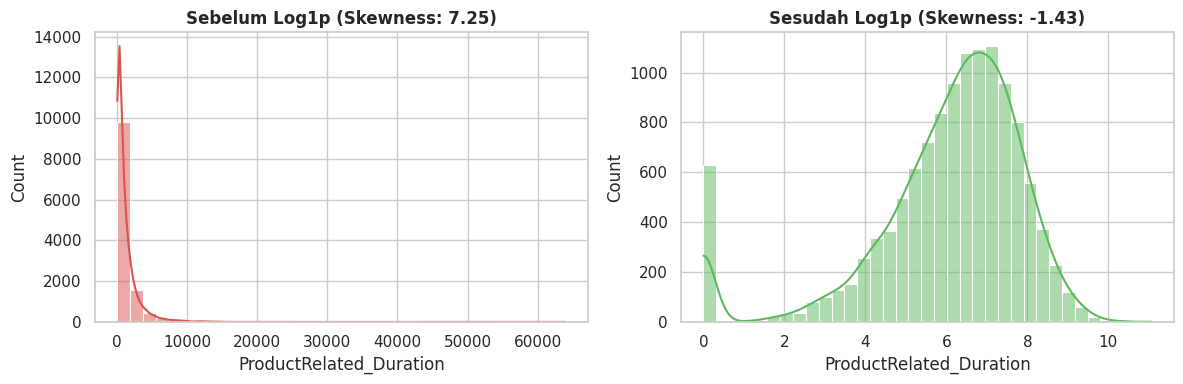


=== 6.2 RINGKASAN RENTANG SETELAH STANDARDSCALER (MEAN=0, STD=1) ===


,ProductRelated,ProductRelated_Duration,PageValues
mean,-0.000,0.000,0.000
std,1.000,1.000,1.000
min,-0.719,-0.629,-0.319
max,15.091,32.699,19.076


=== 6.2 RINGKASAN RENTANG SETELAH MINMAXSCALER (0 HINGGA 1) ===


,ProductRelated,ProductRelated_Duration,PageValues
mean,0.045,0.019,0.016
std,0.063,0.030,0.052
min,0.000,0.000,0.000
max,1.000,1.000,1.000



=== 6.4 CONTOH 5 FITUR BARU HASIL FEATURE ENGINEERING ===


,Total_Pages,Total_Duration,Avg_Time_Per_Page,Product_Page_Ratio,Has_PageValue
0,1,0.000000,0.000000,0.999990,0
1,2,64.000000,31.999840,0.999995,0
2,1,0.000000,0.000000,0.999990,0
3,2,2.666667,1.333327,0.999995,0
4,10,627.500000,62.749937,0.999999,0


In [4]:
# 6.1 Perbandingan Skewness Sebelum dan Sesudah Transformasi Log(x + 1)
skew_comp = pd.DataFrame({
    'Skewness_Sebelum': df[num_cols].skew(),
    'Skewness_Sesudah_Log1p': np.log1p(df[num_cols]).skew()
}).round(3)
print("=== 6.1 PERBANDINGAN SKEWNESS SEBELUM VS SESUDAH LOG1P ===")
display(skew_comp)

# Visualisasi Perbandingan Sebelum vs Sesudah Log1p pada ProductRelated_Duration
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['ProductRelated_Duration'], kde=True, ax=axes[0], color='#d9534f', bins=35)
axes[0].set_title(f"Sebelum Log1p (Skewness: {df['ProductRelated_Duration'].skew():.2f})", fontweight='bold')

sns.histplot(np.log1p(df['ProductRelated_Duration']), kde=True, ax=axes[1], color='#5cb85c', bins=35)
axes[1].set_title(f"Sesudah Log1p (Skewness: {np.log1p(df['ProductRelated_Duration']).skew():.2f})", fontweight='bold')
plt.tight_layout()
plt.show()

# 6.2 Demonstrasi Perbandingan StandardScaler vs MinMaxScaler
demo_cols = ['ProductRelated', 'ProductRelated_Duration', 'PageValues']
df_std = pd.DataFrame(StandardScaler().fit_transform(df[demo_cols]), columns=demo_cols)
df_mm = pd.DataFrame(MinMaxScaler().fit_transform(df[demo_cols]), columns=demo_cols)
print("\n=== 6.2 RINGKASAN RENTANG SETELAH STANDARDSCALER (MEAN=0, STD=1) ===")
display(df_std.describe().loc[['mean', 'std', 'min', 'max']].round(3))
print("=== 6.2 RINGKASAN RENTANG SETELAH MINMAXSCALER (0 HINGGA 1) ===")
display(df_mm.describe().loc[['mean', 'std', 'min', 'max']].round(3))

# 6.4 Pembuatan Fitur Baru (Feature Engineering)
df_fe = df.copy()
df_fe['Total_Pages'] = df_fe['Administrative'] + df_fe['Informational'] + df_fe['ProductRelated']
df_fe['Total_Duration'] = (
    df_fe['Administrative_Duration'] +
    df_fe['Informational_Duration'] +
    df_fe['ProductRelated_Duration']
)
df_fe['Avg_Time_Per_Page'] = df_fe['Total_Duration'] / (df_fe['Total_Pages'] + 1e-5)
df_fe['Product_Page_Ratio'] = df_fe['ProductRelated'] / (df_fe['Total_Pages'] + 1e-5)
df_fe['Has_PageValue'] = (df_fe['PageValues'] > 0).astype(int)

print("\n=== 6.4 CONTOH 5 FITUR BARU HASIL FEATURE ENGINEERING ===")
display(df_fe[['Total_Pages', 'Total_Duration', 'Avg_Time_Per_Page', 'Product_Page_Ratio', 'Has_PageValue']].head())

## Bab 7: Visualisasi Hubungan Data (*Visualizing Relationship of Data*)

### 7.1 Analisis Distribusi Variabel Tunggal (*Univariate Analysis*)
Mengevaluasi proporsi kelas target (`Revenue`) serta sebaran frekuensi variabel kategorikal utama (`Month` dan `VisitorType`).

### 7.2 Analisis Hubungan Antar Variabel (*Bivariate & Multivariate Analysis*)
* **Kategorikal vs Target:** Membandingkan tingkat konversi (%) berdasarkan tipe pengunjung dan bulan kunjungan, dilengkapi uji signifikansi **Chi-Square ($\alpha = 0,05$)**.
* **Numerik vs Kategorikal (`Revenue`):** Membandingkan distribusi fitur perilaku (`ProductRelated_Duration`, `ExitRates`, `BounceRates`, `PageValues`) pada kelas `Revenue = 0` vs `Revenue = 1` menggunakan *Grouped Box Plot* dan **Uji Mann-Whitney U ($\alpha = 0,05$)**.
* **Numerik vs Numerik:** Melihat pola hubungan durasi terhadap jumlah halaman produk melalui *Scatter Plot*.

### 7.3 Analisis Korelasi dan Asosiasi
Menggunakan **Matriks Korelasi Spearman Rank** (karena distribusi data tidak normal/skewed) untuk mendeteksi multikolinearitas antar fitur dan kekuatan asosiasi terhadap target `Revenue`.

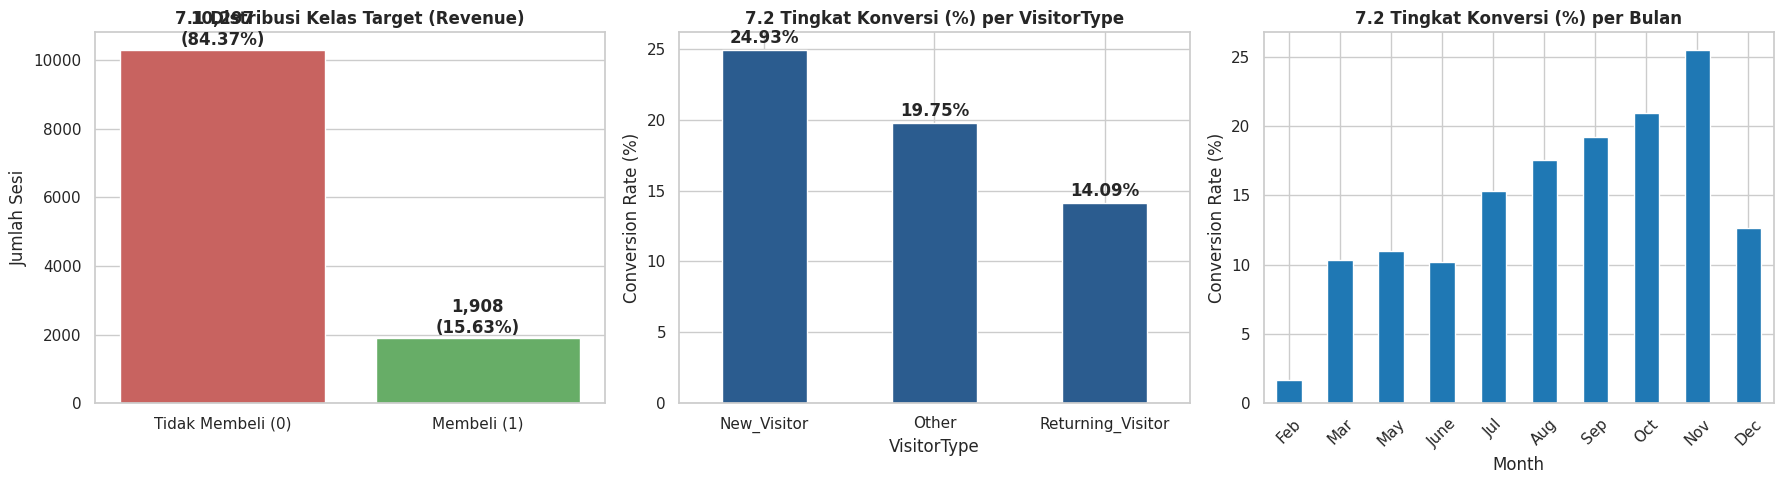

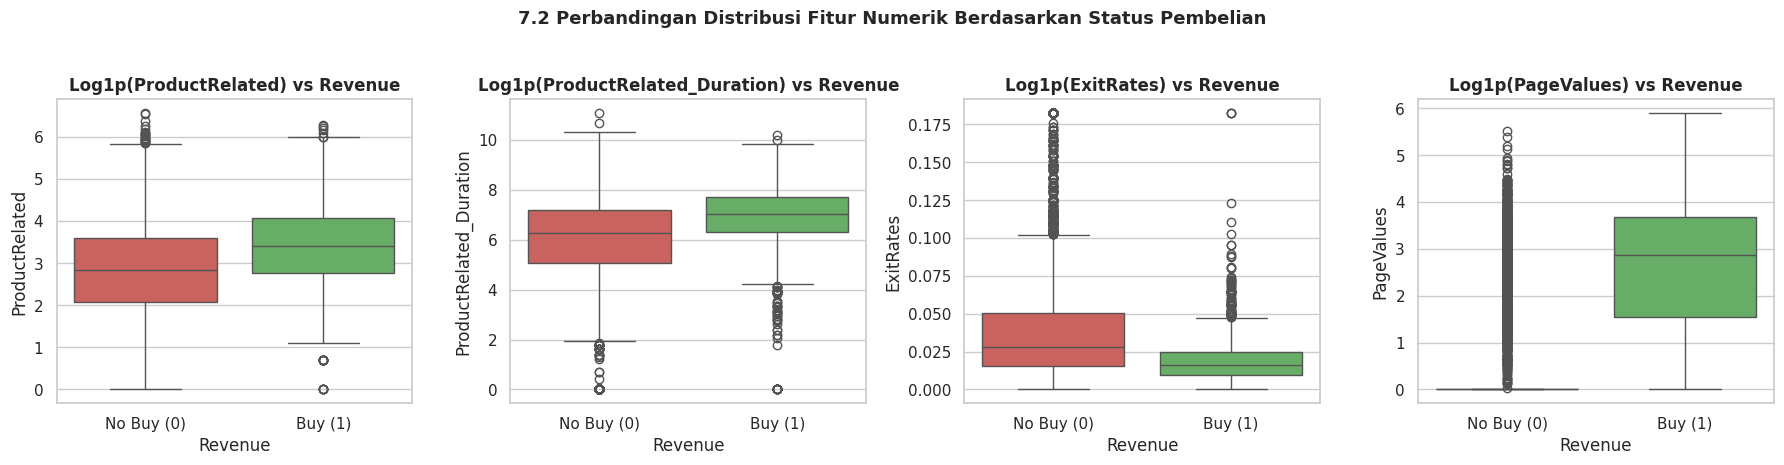

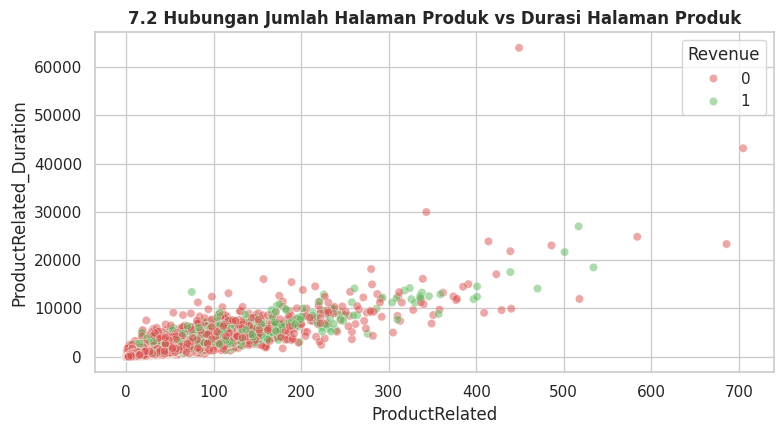

=== UJI MANN-WHITNEY U (NUMERIK VS REVENUE) ===


,Fitur,Median_NoBuy(0),Median_Buy(1),p_value,Signifikan (a=0.05)
0,Administrative,1.0000,2.0000,8.9046e-74,Ya
1,Administrative_Duration,0.0000,52.3667,2.2200e-70,Ya
2,Informational,0.0000,0.0000,4.3654e-35,Ya
3,Informational_Duration,0.0000,0.0000,4.0532e-34,Ya
4,ProductRelated,16.0000,29.0000,3.6936e-102,Ya
5,ProductRelated_Duration,526.0000,1109.9062,4.1833e-122,Ya
6,BounceRates,0.0039,0.0000,1.0601e-56,Ya
7,ExitRates,0.0284,0.0160,3.0299e-169,Ya
8,PageValues,0.0000,16.7581,0.0000e+00,Ya
9,SpecialDay,0.0000,0.0000,1.7405e-22,Ya



=== UJI CHI-SQUARE (KATEGORIKAL VS REVENUE) ===


,Fitur,Chi2_Stat,DoF,p_value,Signifikan (a=0.05)
0,Month,376.280,9,1.5668e-75,Ya
1,OperatingSystems,75.070,7,1.3880e-13,Ya
2,Browser,29.119,12,3.7828e-03,Ya
3,Region,9.679,8,2.8826e-01,Tidak
4,TrafficType,359.225,19,1.2633e-64,Ya
5,VisitorType,130.668,2,4.2256e-29,Ya
6,Weekend,9.205,1,2.4138e-03,Ya


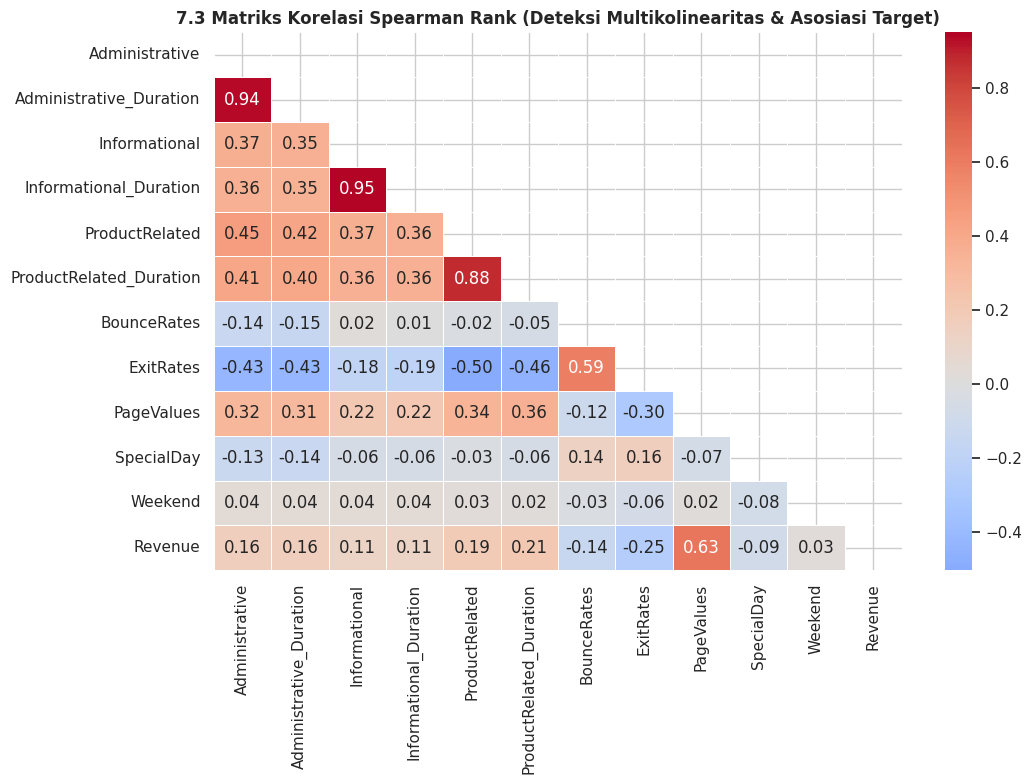

In [5]:
# 7.1 Univariate & 7.2 Bivariate Kategorikal
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Target Revenue
target_counts = df['Revenue'].value_counts()
target_pct = df['Revenue'].value_counts(normalize=True) * 100
sns.barplot(x=['Tidak Membeli (0)', 'Membeli (1)'], y=target_counts.values, ax=axes[0], palette=['#d9534f', '#5cb85c'])
axes[0].set_title('7.1 Distribusi Kelas Target (Revenue)', fontweight='bold')
axes[0].set_ylabel('Jumlah Sesi')
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 150, f"{v:,}\n({target_pct.values[i]:.2f}%)", ha='center', fontweight='bold')

# VisitorType vs Conversion Rate
ct_visitor = pd.crosstab(df['VisitorType'], df['Revenue'], normalize='index') * 100
ct_visitor[1].sort_values(ascending=False).plot(kind='bar', ax=axes[1], color='#2b5c8f')
axes[1].set_title('7.2 Tingkat Konversi (%) per VisitorType', fontweight='bold')
axes[1].set_ylabel('Conversion Rate (%)')
axes[1].tick_params(axis='x', rotation=0)
for i, v in enumerate(ct_visitor[1].sort_values(ascending=False).values):
    axes[1].text(i, v + 0.5, f"{v:.2f}%", ha='center', fontweight='bold')

# Month vs Conversion Rate
month_order = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
ct_month = pd.crosstab(df['Month'], df['Revenue'], normalize='index').reindex(month_order) * 100
ct_month[1].plot(kind='bar', ax=axes[2], color='#1f78b4')
axes[2].set_title('7.2 Tingkat Konversi (%) per Bulan', fontweight='bold')
axes[2].set_ylabel('Conversion Rate (%)')
axes[2].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

# 7.2 Bivariate Numerik vs Kategorikal (Grouped Box Plot dalam skala Log1p agar jelas)
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
biv_cols = ['ProductRelated', 'ProductRelated_Duration', 'ExitRates', 'PageValues']
for i, col in enumerate(biv_cols):
    sns.boxplot(x=df['Revenue'], y=np.log1p(df[col]), ax=axes[i], palette=['#d9534f', '#5cb85c'])
    axes[i].set_title(f"Log1p({col}) vs Revenue", fontweight='bold')
    axes[i].set_xticklabels(['No Buy (0)', 'Buy (1)'])
plt.suptitle("7.2 Perbandingan Distribusi Fitur Numerik Berdasarkan Status Pembelian", fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# 7.2 Bivariate Numerik vs Numerik (Scatterplot)
plt.figure(figsize=(8, 4.5))
sns.scatterplot(data=df, x='ProductRelated', y='ProductRelated_Duration', hue='Revenue', alpha=0.5, palette=['#d9534f', '#5cb85c'])
plt.title("7.2 Hubungan Jumlah Halaman Produk vs Durasi Halaman Produk", fontweight='bold')
plt.tight_layout()
plt.show()

# Uji Hipotesis Statistik (Mann-Whitney U & Chi-Square pada alpha = 0.05)
print("=== UJI MANN-WHITNEY U (NUMERIK VS REVENUE) ===")
mw_results = []
for col in num_cols:
    g0 = df[df['Revenue'] == 0][col]
    g1 = df[df['Revenue'] == 1][col]
    _, p_val = stats.mannwhitneyu(g0, g1, alternative='two-sided')
    mw_results.append({
        'Fitur': col, 'Median_NoBuy(0)': round(g0.median(), 4),
        'Median_Buy(1)': round(g1.median(), 4), 'p_value': f"{p_val:.4e}",
        'Signifikan (a=0.05)': 'Ya' if p_val < 0.05 else 'Tidak'
    })
display(pd.DataFrame(mw_results))

print("\n=== UJI CHI-SQUARE (KATEGORIKAL VS REVENUE) ===")
cat_cols = ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']
chi_results = []
for col in cat_cols:
    ct = pd.crosstab(df[col], df['Revenue'])
    chi2, p_val, dof, _ = stats.chi2_contingency(ct)
    chi_results.append({
        'Fitur': col, 'Chi2_Stat': round(chi2, 3), 'DoF': dof,
        'p_value': f"{p_val:.4e}", 'Signifikan (a=0.05)': 'Ya' if p_val < 0.05 else 'Tidak'
    })
display(pd.DataFrame(chi_results))

# 7.3 Analisis Korelasi Spearman Rank
plt.figure(figsize=(11, 8))
corr_matrix = df[num_cols + ['Weekend', 'Revenue']].corr(method='spearman')
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("7.3 Matriks Korelasi Spearman Rank (Deteksi Multikolinearitas & Asosiasi Target)", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## Bab 8: Penanganan Pencilan (*Handling Outliers*)

### 8.1 Metode Deteksi Pencilan
Karena seluruh variabel numerik berdistribusi *skewed* (tidak normal), digunakan pendekatan **Interquartile Range (IQR)** dengan batas bawah $Q1 - 1,5 \times IQR$ dan batas atas $Q3 + 1,5 \times IQR$, disertai visualisasi **Box Plot**.

### 8.2 Keputusan Perlakuan Terhadap Pencilan (*Treatment Decisions*)
* **Strategi yang Dipilih: Dipertahankan (*Retention*)** (disertai transformasi `Log1p` khusus pada *pipeline* model linear *Logistic Regression*).
* **Justifikasi Bisnis (*Domain Knowledge*):** Nilai ekstrem pada `PageValues`, `ProductRelated`, dan `ProductRelated_Duration` **bukan merupakan kesalahan input**, melainkan representasi perilaku pengguna berniat beli tinggi (*high-intent shoppers*) yang membandingkan banyak produk sebelum *checkout*. Menghapus atau memotong (*trimming/capping*) nilai ini justru akan menghilangkan sinyal paling krusial untuk mendeteksi konversi pembelian. Selain itu, model utama yang direkomendasikan (**XGBoost**) bersifat non-parametrik berbasis pohon sehingga tangguh (*robust*) terhadap *outlier*.

=== 8.1 TABEL DETEKSI PENCILAN MENGGUNAKAN METODE IQR ===


,Fitur,Q1,Q3,IQR,Batas_Atas_IQR,Jumlah_Outlier,Persentase_Outlier (%)
0,Administrative,0.000,4.000,4.000,10.000,404,3.31
1,Administrative_Duration,0.000,94.700,94.700,236.750,1149,9.41
2,Informational,0.000,0.000,0.000,0.000,2631,21.56
3,Informational_Duration,0.000,0.000,0.000,0.000,2405,19.71
4,ProductRelated,8.000,38.000,30.000,83.000,1007,8.25
5,ProductRelated_Duration,193.000,1477.155,1284.155,3403.387,951,7.79
6,BounceRates,0.000,0.017,0.017,0.042,1428,11.70
7,ExitRates,0.014,0.049,0.034,0.100,1325,10.86
8,PageValues,0.000,0.000,0.000,0.000,2730,22.37
9,SpecialDay,0.000,0.000,0.000,0.000,1249,10.23


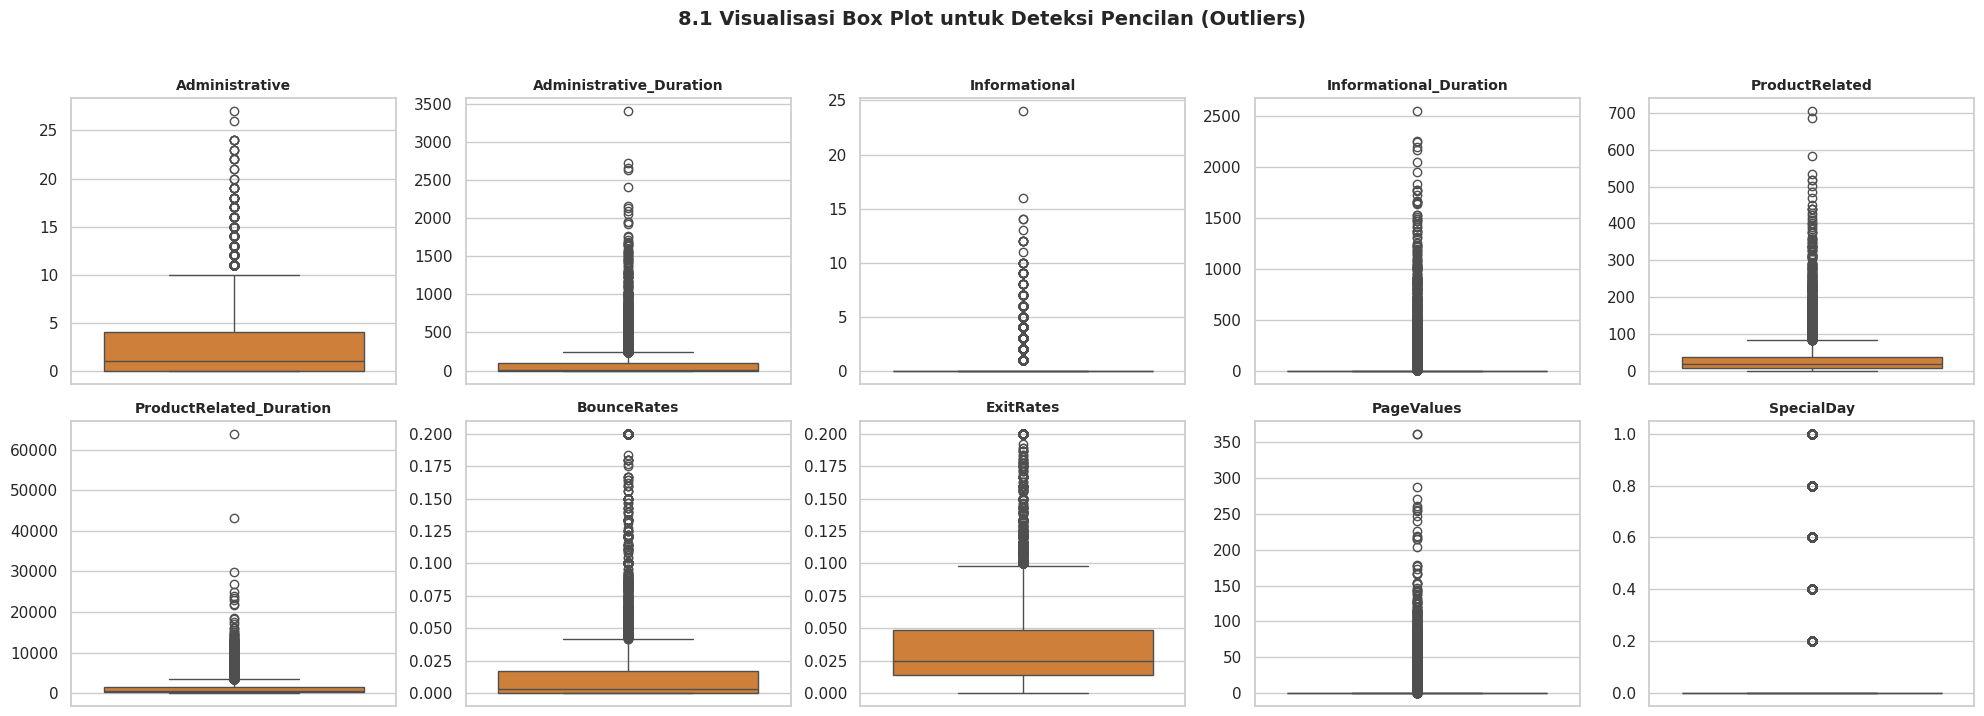

In [6]:
# 8.1 Deteksi Pencilan dengan Metode IQR
outlier_summary = []
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outlier_summary.append({
        'Fitur': col,
        'Q1': round(Q1, 3),
        'Q3': round(Q3, 3),
        'IQR': round(IQR, 3),
        'Batas_Atas_IQR': round(upper_bound, 3),
        'Jumlah_Outlier': len(outliers),
        'Persentase_Outlier (%)': round((len(outliers) / len(df)) * 100, 2)
    })

print("=== 8.1 TABEL DETEKSI PENCILAN MENGGUNAKAN METODE IQR ===")
display(pd.DataFrame(outlier_summary))

# Visualisasi Box Plot Sebaran Pencilan
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
axes = axes.flatten()
for idx, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[idx], color='#e67e22')
    axes[idx].set_title(col, fontsize=10, fontweight='bold')
    axes[idx].set_ylabel("")

plt.suptitle("8.1 Visualisasi Box Plot untuk Deteksi Pencilan (Outliers)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

,Model,ROC-AUC,F1-Score (Kelas 1),Recall,Precision
0,Logistic Regression (Baseline),0.9268,0.6646,0.8508,0.5453
1,XGBoost Classifier (Cost-Sensitive),0.9343,0.6638,0.8089,0.5628


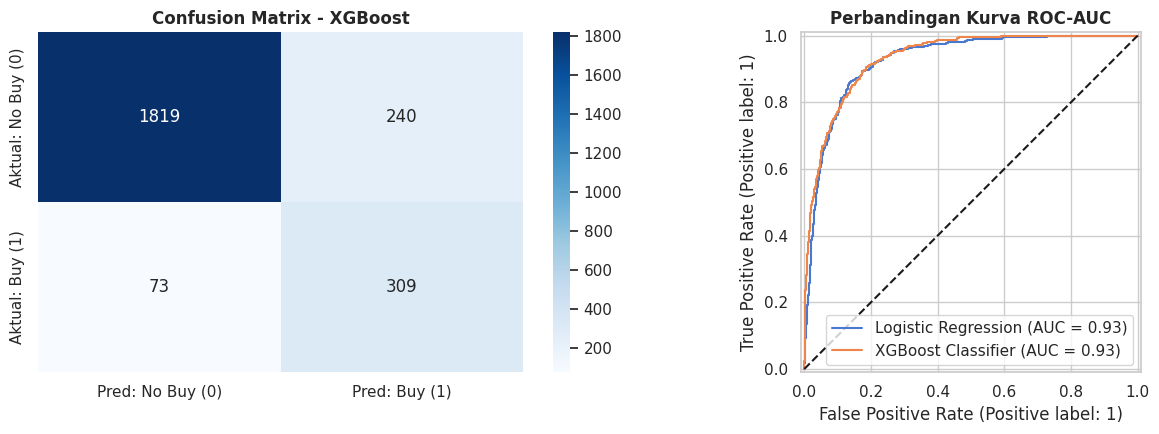

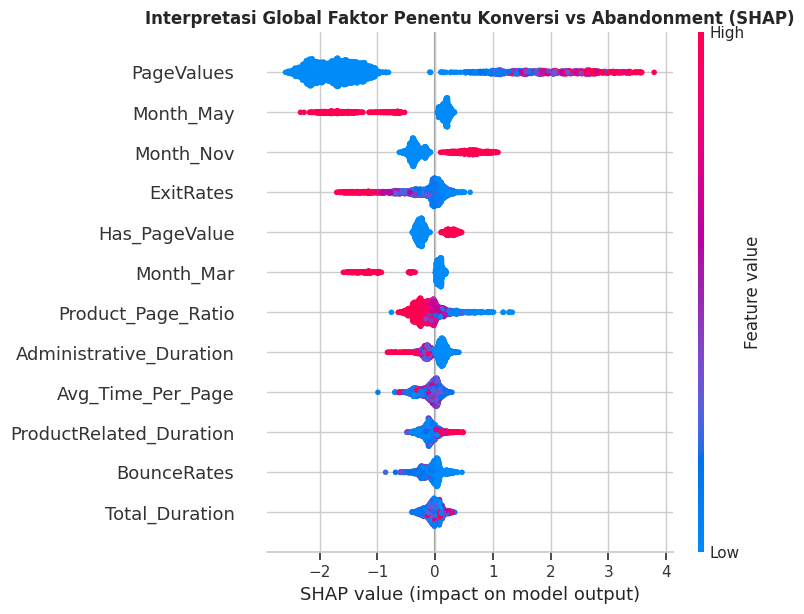

In [7]:
# Persiapan Fitur & Stratified Train-Test Split (80% Train, 20% Test)
nominal_features = ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType']
for col in nominal_features:
    df_fe[col] = df_fe[col].astype(str)

numeric_features = num_cols + [
    'Weekend', 'Total_Pages', 'Total_Duration',
    'Avg_Time_Per_Page', 'Product_Page_Ratio', 'Has_PageValue'
]

X = df_fe[numeric_features + nominal_features]
y = df_fe['Revenue']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Pipeline 1: Logistic Regression (Log1p + StandardScaler + OneHotEncoder + Class Weight Balanced)
log_transformer = FunctionTransformer(lambda x: np.log1p(np.maximum(x, 0)))
preprocessor_lr = ColumnTransformer(transformers=[
    ('num', Pipeline([('log', log_transformer), ('scaler', StandardScaler())]), numeric_features),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), nominal_features)
])
model_lr = Pipeline([
    ('prep', preprocessor_lr),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])
model_lr.fit(X_train, y_train)

# Pipeline 2: XGBoost Classifier (Cost-Sensitive scale_pos_weight)
preprocessor_xgb = ColumnTransformer(transformers=[
    ('num', 'passthrough', numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), nominal_features)
])
X_train_enc = preprocessor_xgb.fit_transform(X_train)
X_test_enc = preprocessor_xgb.transform(X_test)
clean_names = [n.replace('num__', '').replace('cat__', '') for n in preprocessor_xgb.get_feature_names_out()]

X_train_df = pd.DataFrame(X_train_enc.toarray() if hasattr(X_train_enc, "toarray") else X_train_enc, columns=clean_names)
X_test_df = pd.DataFrame(X_test_enc.toarray() if hasattr(X_test_enc, "toarray") else X_test_enc, columns=clean_names)

scale_weight = (y_train == 0).sum() / (y_train == 1).sum()
xgb_clf = xgb.XGBClassifier(
    n_estimators=250, max_depth=5, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, scale_pos_weight=scale_weight,
    eval_metric='logloss', random_state=42, n_jobs=-1
)
xgb_clf.fit(X_train_df, y_train)

# Evaluasi Perbandingan Model
y_pred_lr, y_prob_lr = model_lr.predict(X_test), model_lr.predict_proba(X_test)[:, 1]
y_pred_xgb, y_prob_xgb = xgb_clf.predict(X_test_df), xgb_clf.predict_proba(X_test_df)[:, 1]

eval_df = pd.DataFrame([
    {'Model': 'Logistic Regression (Baseline)', 'ROC-AUC': round(roc_auc_score(y_test, y_prob_lr), 4),
     'F1-Score (Kelas 1)': round(f1_score(y_test, y_pred_lr), 4), 'Recall': round(recall_score(y_test, y_pred_lr), 4),
     'Precision': round(precision_score(y_test, y_pred_lr), 4)},
    {'Model': 'XGBoost Classifier (Cost-Sensitive)', 'ROC-AUC': round(roc_auc_score(y_test, y_prob_xgb), 4),
     'F1-Score (Kelas 1)': round(f1_score(y_test, y_pred_xgb), 4), 'Recall': round(recall_score(y_test, y_pred_xgb), 4),
     'Precision': round(precision_score(y_test, y_pred_xgb), 4)}
])
display(eval_df)

# Visualisasi Confusion Matrix, ROC-AUC, & SHAP Summary Plot
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(confusion_matrix(y_test, y_pred_xgb), annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Pred: No Buy (0)', 'Pred: Buy (1)'], yticklabels=['Aktual: No Buy (0)', 'Aktual: Buy (1)'])
axes[0].set_title('Confusion Matrix - XGBoost', fontweight='bold')

RocCurveDisplay.from_predictions(y_test, y_prob_lr, name='Logistic Regression', ax=axes[1])
RocCurveDisplay.from_predictions(y_test, y_prob_xgb, name='XGBoost Classifier', ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_title('Perbandingan Kurva ROC-AUC', fontweight='bold')
plt.tight_layout()
plt.show()

# SHAP Explainability untuk Melihat Fitur Paling Berpengaruh
explainer = shap.TreeExplainer(xgb_clf)
shap_values = explainer.shap_values(X_test_df)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_df, max_display=12, show=False)
plt.title("Interpretasi Global Faktor Penentu Konversi vs Abandonment (SHAP)", fontweight='bold')
plt.tight_layout()
plt.show()

## Bab 9: Kesimpulan & Temuan Utama (*Communicate Findings and Insights*)

### 9.1 Rangkuman Temuan Utama (*Key Insights & Patterns*)
1. **Pola Dominan (*Class Imbalance*):** Dari 12.205 sesi unik, sebanyak **84,37% (10.297 sesi)** berakhir tanpa transaksi (*cart/session abandonment*), sedangkan hanya **15,63% (1.908 sesi)** yang berujung pembelian (`Revenue = 1`).
2. **Prediktor Terkuat Konversi:** Berdasarkan uji Mann-Whitney U ($p < 0,0001$), korelasi Spearman ($r = 0,63$), dan analisis SHAP, variabel **`PageValues`** (dan fitur turunan `Has_PageValue`) merupakan pembeda paling tajam. Sesi pembelian memiliki median `PageValues` sebesar **16,76**, sedangkan sesi yang ditinggalkan memiliki median **0,00**.
3. **Kedalaman Eksplorasi vs Tingkat Keluar:** Pengunjung yang membeli membuka halaman produk hampir dua kali lebih banyak (median **29 halaman** vs **16 halaman**) dan menghabiskan waktu lebih dari dua kali lipat (median **1.109,9 detik** vs **526,0 detik**). Sebaliknya, sesi yang ditinggalkan memiliki nilai `ExitRates` (median **0,0284** vs **0,0160**) dan `BounceRates` yang jauh lebih tinggi.
4. **Anomali & Pola Segmen Pengunjung:** Meskipun pengunjung lama (*Returning Visitor*) mendominasi volume trafik, tingkat konversi tertinggi justru dicapai oleh segmen **`Other` (19,75%)** dan **`New_Visitor` (24,91%)**, sementara lonjakan transaksi musiman memuncak pada bulan **November** (periode promo akhir tahun). Sementara itu, variabel `Region` terbukti **tidak signifikan** ($p = 0,288 > 0,05$).

### 9.2 Keterbatasan dan Kendala Analisis (*Limitations & Constraints*)
1. **Ketiadaan Data Demografi & Nominal Keranjang:** Dataset hanya merekam metrik perilaku klik (*clickstream*) anonim tanpa informasi harga barang, diskon, metode pembayaran, atau profil demografi pengguna.
2. **Distribusi Sangat Condong (*Extreme Skewness*) & Imbalanced Target:** Banyak fitur bernilai nol pada kuartil bawah ($Q1 = 0$) dan proporsi kelas positif hanya 15,63%, sehingga memerlukan penanganan pembobotan biaya kesalahan (*cost-sensitive learning*).
3. **Ketiadaan Identitas Pengguna Lintas Sesi:** Data bersifat *session-level* sehingga tidak dapat melacak apakah pengguna yang meninggalkan keranjang kembali membeli pada sesi berikutnya.

### 9.3 Rekomendasi Langkah Selanjutnya (*Next Steps & Model Recommendations*)
1. **Rekomendasi Model Utama:** Menggunakan **XGBoost Classifier dengan Cost-Sensitive Learning (`scale_pos_weight`)** yang dipadukan dengan **SHAP**. Model ini terbukti unggul dengan skor **ROC-AUC 0,9343** dan **Recall 80,89%**, mampu menangkap interaksi non-linear antar fitur perilaku, serta tahan terhadap *outlier* alami.
2. **Rekomendasi Rekayasa Fitur & Penanganan Imbalance Lanjutan:** Pada tahap pengembangan berikutnya, dapat dilakukan penyetelan ambang batas probabilitas (*threshold tuning*) atau eksperimen teknik *oversampling* seperti **SMOTE-NC** pada data latih untuk meningkatkan nilai *Precision* tanpa mengorbankan *Recall*.
3. **Rekomendasi Intervensi Bisnis:** Mengintegrasikan skor probabilitas model ke dalam sistem *real-time trigger* (misalnya memunculkan *pop-up* voucher gratis ongkir atau pengingat stok ketika `Has_PageValue = 1` namun `ExitRates` mulai meningkat).